## Data acquisition and justification
This analysis uses the NHTSA Standing General Order Level 2 ADAS incident-reporting dataset. It is relevant because it contains reported crashes involving driver-assistance systems, including Tesla vehicles. It is observational reporting data, not exposure-adjusted risk data.

## Import libraries

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from pathlib import Path
from scipy.stats import chi2_contingency
from IPython.display import display, Markdown

pd.set_option("display.max_columns", 30)
pd.set_option("display.max_colwidth", 100)

print("Libraries imported successfully.")

Libraries imported successfully.


## Load downloaded dataset


In [2]:
file_path = Path("SGO-2021-01_Incident_Reports_ADAS.csv")

if not file_path.exists():
    file_path = Path("/mnt/data/SGO-2021-01_Incident_Reports_ADAS.csv")

if not file_path.exists():
    raise FileNotFoundError(
        "CSV not found. Update file_path to your downloaded CSV location."
    )

df = pd.read_csv(file_path, low_memory=False)

print("Dataset loaded successfully.")
print("Rows:", df.shape[0])
print("Columns:", df.shape[1])

Dataset loaded successfully.
Rows: 2574
Columns: 116


## Initial data inspection
The initial inspection identifies the dataset dimensions, column names, data types and sample records. This establishes what information is available before cleaning and helps determine whether the fields support the proposed research question.

### Inspect the dataset

In [3]:
display(df.head())

print("Dataset dimensions:", df.shape)

print("\nColumn names:")
print(df.columns.tolist())

print("\nData types:")
display(df.dtypes.value_counts().rename("Number of columns").to_frame())

,Report ID,Report Version,Reporting Entity,Report Type,Report Month,Report Year,Report Submission Date,VIN,VIN Decoded,Serial Number,Make,Make - Unknown,Model,Model - Unknown,Model Year,...,SV Contact Area - Unknown,Data Availability - EDR,Data Availability - Police Rpt,Data Availability - Telematics,Data Availability - Complaints,Data Availability - Video,Data Availability - Other,Data Availability - No Data,Data Availability - Unknown,Investigating Agency,Investigating Agency - Unknown,Within ODD?,Within ODD? - CBI,Narrative,Narrative - CBI?
0,753-15357,2,"Kia America, Inc.",Update,NaN,NaN,SEP-2026,5XYRHDLF2NG,Y,[MAY CONTAIN PERSONALLY IDENTIFIABLE INFORMATION],KIA,,Sorento,,2022,...,,,,,Y,,,,,NaN,Y,"Unknown, see Narrative",,"**6/9/2026 5-Day Incident Report**\nOn June 4, 2026, the customer called Kia's Customer Care Cen...",
1,502-16641,1,Ford Motor Company,5-Day,NaN,NaN,SEP-2026,1FTFW3L87RK,Y,[MAY CONTAIN PERSONALLY IDENTIFIABLE INFORMATION],FORD,,F-150,,2024,...,,,,Y,,,,,,NaN,Y,Yes,,"On September 14, 2026, Ford received telematics data indicating that on September [XXX], 2026, a...",
2,13781-16693,1,"Tesla, Inc.",5-Day,NaN,NaN,SEP-2026,7SAYGDED3RF,Y,[MAY CONTAIN PERSONALLY IDENTIFIABLE INFORMATION],TESLA,,Model Y,,2024,...,Y,Y,,,,Y,Y,,,NaN,Y,"[REDACTED, MAY CONTAIN CONFIDENTIAL BUSINESS INFORMATION]",Y,"[REDACTED, MAY CONTAIN CONFIDENTIAL BUSINESS INFORMATION]",Y
3,13781-16692,1,"Tesla, Inc.",5-Day,NaN,NaN,SEP-2026,7SAYGDEF2RF,Y,[MAY CONTAIN PERSONALLY IDENTIFIABLE INFORMATION],TESLA,,Model Y,,2024,...,Y,Y,,Y,,,Y,,,NaN,Y,"[REDACTED, MAY CONTAIN CONFIDENTIAL BUSINESS INFORMATION]",Y,"[REDACTED, MAY CONTAIN CONFIDENTIAL BUSINESS INFORMATION]",Y
4,13781-16691,1,"Tesla, Inc.",5-Day,NaN,NaN,SEP-2026,5YJ3E1EA4LF,Y,[MAY CONTAIN PERSONALLY IDENTIFIABLE INFORMATION],TESLA,,Model 3,,2020,...,,Y,,Y,,Y,Y,,,NaN,Y,"[REDACTED, MAY CONTAIN CONFIDENTIAL BUSINESS INFORMATION]",Y,"[REDACTED, MAY CONTAIN CONFIDENTIAL BUSINESS INFORMATION]",Y


Dataset dimensions: (2574, 116)

Column names:
['Report ID', 'Report Version', 'Reporting Entity', 'Report Type', 'Report Month', 'Report Year', 'Report Submission Date', 'VIN', 'VIN Decoded', 'Serial Number', 'Make', 'Make - Unknown', 'Model', 'Model - Unknown', 'Model Year', 'Model Year - Unknown', 'Same Vehicle ID', 'Driver / Operator Type', 'Automation Feature Version', 'Automation Feature Version CBI', 'Automation System Engaged?', 'Engagement Status', 'Operating Entity', 'Operating Entity - Unknown', 'Source - Complaint/Claim', 'Source - Telematics', 'Source - Law Enforcement', 'Source - Field Report', 'Source - Testing', 'Source - Media', 'Source - Internal Process Review', 'Source - NHTSA VOQ', 'Source - Other - See Narrative', 'Source - Other Entity', 'Source - State or Other Agency', 'Incident Date', 'Incident Date - Unknown', 'Incident Time (24:00)', 'Incident Time - Unknown', 'Same Incident ID', 'Latitude', 'Latitude - Unknown', 'Longitude', 'Longitude - Unknown', 'Address'

,Number of columns
object,111
float64,3
int64,2


### Check required fields

In [4]:
required_columns = [
    "Report ID",
    "Report Version",
    "Report Submission Date",
    "Make",
    "Same Incident ID",
    "Incident Date",
    "Roadway Type",
    "Crash With",
    "Engagement Status",
    "Highest Injury Severity Alleged"
]

missing_columns = [
    col for col in required_columns if col not in df.columns
]

if missing_columns:
    raise ValueError(f"Required columns not found: {missing_columns}")

print("All required analysis columns are available.")

All required analysis columns are available.


## Data cleaning and preparation
This stage standardises blank values, checks missing information and identifies repeated reports. Missing and unknown values are distinguished from genuine observations so that incomplete records are not mistakenly interpreted as confirmed crash characteristics.

### Standardise blank values and inspect missingness

In [5]:
# Convert cells containing only spaces into missing values
df = df.replace(r"^\s*$", pd.NA, regex=True)

missing_summary = (
    df.isna()
      .sum()
      .sort_values(ascending=False)
      .rename("Missing values")
      .to_frame()
)

display(missing_summary.head(15))

print("Rows before cleaning:", len(df))

,Missing values
City - Unknown,2574
Roadway-Degraded Surface,2574
Address - Unknown,2574
Source - State or Other Agency,2574
Source - Other - See Narrative,2574
Zip Code - Unknown,2574
Make - Unknown,2574
Weather - Dust Storm,2574
Model - Unknown,2574
Weather - Severe Hurricane,2574


Rows before cleaning: 2574


### Keep the latest report versions
Some report IDs can appear more than once because updated reports may be submitted. This cell keeps the highest report version for each report ID, using the submission date to break ties.

In [6]:
df["Report Version"] = pd.to_numeric(
    df["Report Version"], errors="coerce"
)

df["Submission Month"] = pd.to_datetime(
    df["Report Submission Date"],
    format="%b-%Y",
    errors="coerce"
)

df_clean = (
    df.sort_values(["Report Version", "Submission Month"])
      .drop_duplicates(subset=["Report ID"], keep="last")
      .copy()
)

print("Original records:", len(df))
print("After keeping latest report versions:", len(df_clean))
print("Remaining duplicate Report IDs:",
      df_clean["Report ID"].duplicated().sum())

Original records: 2574
After keeping latest report versions: 2427
Remaining duplicate Report IDs: 0


### Select Tesla records and handle repeated incident IDs
This creates the Tesla case-study dataset. Where a Tesla incident ID appears more than once, only its latest available report is retained. Records without an incident ID are preserved separately rather than being incorrectly grouped together.

In [7]:
tesla = df_clean[
    df_clean["Make"].astype("string").str.strip().str.upper().eq("TESLA")
].copy()

tesla["_incident_key"] = tesla["Same Incident ID"].astype("string")

missing_id = tesla["_incident_key"].isna()
tesla.loc[missing_id, "_incident_key"] = [
    f"MISSING_{i}" for i in tesla.index[missing_id]
]

tesla = (
    tesla.sort_values(["Report Version", "Submission Month"])
         .drop_duplicates("_incident_key", keep="last")
         .copy()
)

print("Tesla records after cleaning:", len(tesla))
print("Unique incident keys:", tesla["_incident_key"].nunique())

Tesla records after cleaning: 2164
Unique incident keys: 2164


### Check data quality in important variables

In [8]:
key_columns = [
    "Incident Date",
    "Roadway Type",
    "Crash With",
    "Engagement Status",
    "Highest Injury Severity Alleged"
]

quality_rows = []

for col in key_columns:
    values = tesla[col].astype("string").str.strip()

    missing_count = values.isna().sum()
    unknown_count = values.str.contains(
        "unknown", case=False, na=False
    ).sum()

    quality_rows.append({
        "Variable": col,
        "Missing": int(missing_count),
        "Unknown-labelled": int(unknown_count),
        "Available values": int(len(tesla) - missing_count - unknown_count)
    })

quality_table = pd.DataFrame(quality_rows)
display(quality_table)

,Variable,Missing,Unknown-labelled,Available values
0,Incident Date,0,0,2164
1,Roadway Type,0,900,1264
2,Crash With,0,1200,964
3,Engagement Status,0,0,2164
4,Highest Injury Severity Alleged,0,2080,84


## Descriptive statistical analysis
Descriptive statistics summarise Tesla incident reports by roadway type, collision partner, engagement status and alleged injury severity. These tables reveal reporting patterns and data limitations before inferential testing, without implying that counts measure crash risk.

### Summarise key categorical variables

In [9]:
def frequency_table(data, column):
    result = (
        data[column]
        .fillna("Missing")
        .astype(str)
        .str.strip()
        .replace("", "Missing")
        .value_counts(dropna=False)
        .rename_axis(column)
        .reset_index(name="Count")
    )

    result["Percentage"] = (
        result["Count"] / result["Count"].sum() * 100
    ).round(2)

    return result

for column in [
    "Roadway Type",
    "Crash With",
    "Engagement Status",
    "Highest Injury Severity Alleged"
]:
    print(f"\n{column}")
    display(frequency_table(tesla, column).head(12))


Roadway Type


,Roadway Type,Count,Percentage
0,Unknown,900,41.59
1,Highway / Freeway,691,31.93
2,Intersection,250,11.55
3,Street,242,11.18
4,Rural Road,42,1.94
5,Parking Lot,29,1.34
6,Parking Garage,6,0.28
7,Unpaved Road,2,0.09
8,Traffic Circle,2,0.09



Crash With


,Crash With,Count,Percentage
0,Unknown,1200,55.45
1,Other Fixed Object,310,14.33
2,Passenger Car,215,9.94
3,SUV,168,7.76
4,Pickup Truck,73,3.37
5,"Other, see Narrative",72,3.33
6,Pole / Tree,52,2.40
7,Heavy Truck,23,1.06
8,Animal,13,0.60
9,Van,12,0.55



Engagement Status


,Engagement Status,Count,Percentage
0,Verified Engaged,2158,99.72
1,Verified Not Engaged,4,0.18
2,Alleged Engaged,2,0.09



Highest Injury Severity Alleged


,Highest Injury Severity Alleged,Count,Percentage
0,Unknown,2080,96.12
1,Fatality,21,0.97
2,No Injured Reported,16,0.74
3,Minor W/ Hospitalization,15,0.69
4,Serious W/ Hospitalization,12,0.55
5,Property Damage. No Injured Reported,10,0.46
6,Minor W/O Hospitalization,7,0.32
7,Moderate W/ Hospitalization,2,0.09
8,Serious W/O Hospitalization,1,0.05


### Visualise reported roadway types 

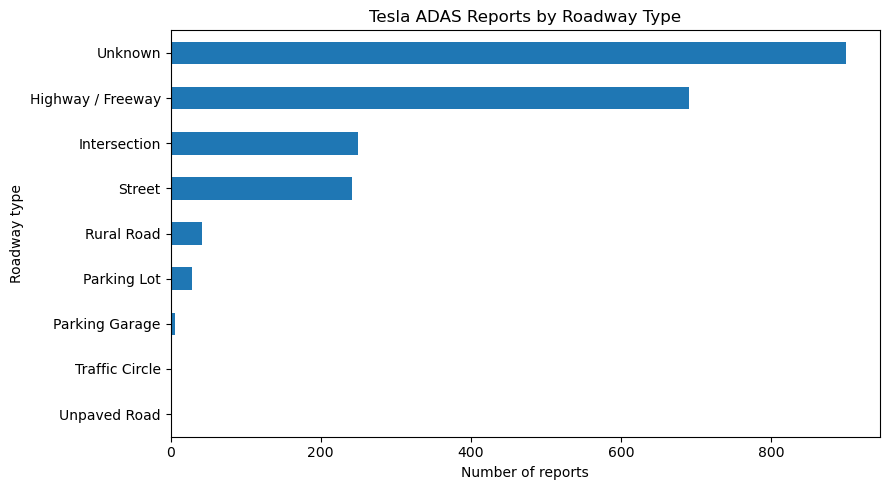

In [10]:
road_counts = (
    tesla["Roadway Type"]
    .fillna("Missing")
    .astype(str)
    .str.strip()
    .value_counts()
    .head(10)
    .sort_values()
)

plt.figure(figsize=(9, 5))
road_counts.plot(kind="barh")
plt.title("Tesla ADAS Reports by Roadway Type")
plt.xlabel("Number of reports")
plt.ylabel("Roadway type")
plt.tight_layout()
plt.show()

### Visualise reported collision partners

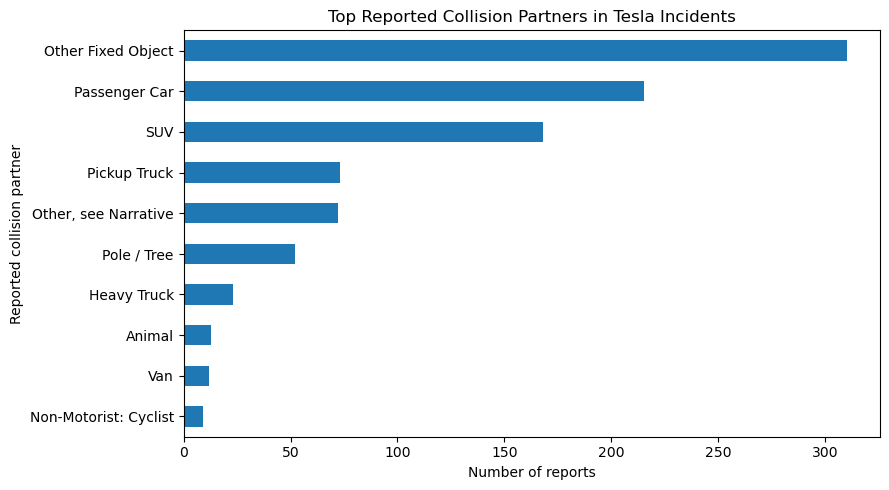

In [11]:
crash_counts = (
    tesla["Crash With"]
    .dropna()
    .astype(str)
    .str.strip()
)

crash_counts = crash_counts[
    ~crash_counts.str.contains("unknown", case=False, na=False)
]

crash_counts = crash_counts.value_counts().head(10).sort_values()

plt.figure(figsize=(9, 5))
crash_counts.plot(kind="barh")
plt.title("Top Reported Collision Partners in Tesla Incidents")
plt.xlabel("Number of reports")
plt.ylabel("Reported collision partner")
plt.tight_layout()
plt.show()

### Examine the distribution of incident dates
The dataset's incident dates may contain only month and year rather than an exact date. This chart therefore shows monthly reporting patterns in the incident-date field, not precise daily crash trends.

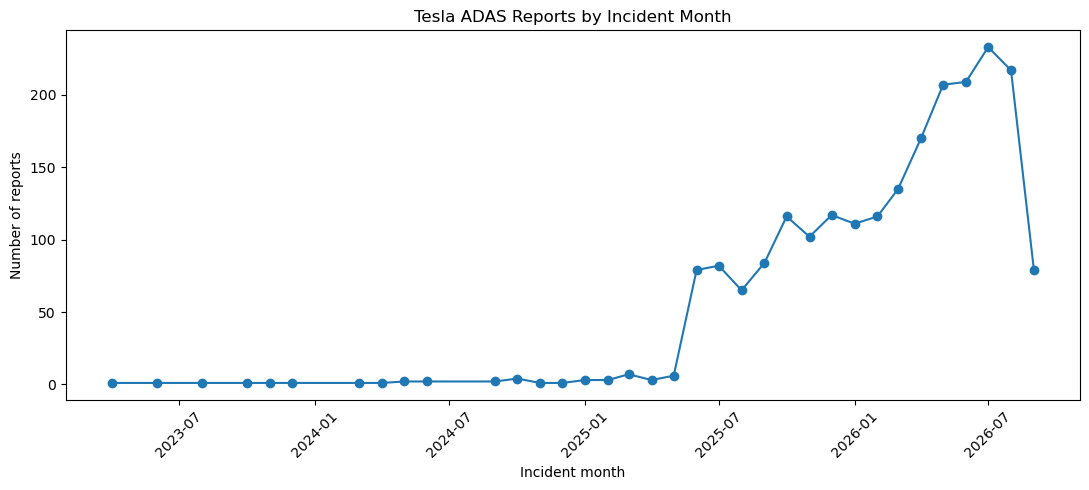

In [12]:
tesla["Incident Month"] = pd.to_datetime(
    tesla["Incident Date"],
    format="%b-%Y",
    errors="coerce"
)

monthly_counts = (
    tesla.dropna(subset=["Incident Month"])
         .groupby("Incident Month")
         .size()
         .sort_index()
)

plt.figure(figsize=(11, 5))
plt.plot(monthly_counts.index, monthly_counts.values, marker="o")
plt.title("Tesla ADAS Reports by Incident Month")
plt.xlabel("Incident month")
plt.ylabel("Number of reports")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

## Chi-square test of association
The chi-square test assesses whether roadway type and reported collision partner are statistically associated among eligible Tesla incident records. Unknown categories are excluded, rare known collision-partner categories are combined, and the test's expected-frequency assumptions are checked.
We will compare three common roadway types — highway/freeway, intersection and street — against five collision-partner groups. This keeps the analysis interpretable while excluding rare roadway categories from the inferential test.

### Prepare the chi-square dataset

In [13]:
analysis = tesla.copy()

analysis["Roadway Clean"] = (
    analysis["Roadway Type"]
    .fillna("")
    .astype(str)
    .str.strip()
)

analysis["Crash Clean"] = (
    analysis["Crash With"]
    .fillna("")
    .astype(str)
    .str.strip()
)

# Keep the three main roadway categories
road_types = ["Highway / Freeway", "Intersection", "Street"]

analysis = analysis[
    analysis["Roadway Clean"].isin(road_types)
].copy()

# Exclude missing or unknown collision-partner information
analysis = analysis[
    analysis["Crash Clean"].ne("") &
    ~analysis["Crash Clean"].str.contains(
        "unknown", case=False, na=False
    )
].copy()

# Preserve common categories and combine other known categories
common_partners = [
    "Other Fixed Object",
    "Passenger Car",
    "SUV",
    "Pickup Truck"
]

analysis["Crash Partner Group"] = analysis["Crash Clean"].where(
    analysis["Crash Clean"].isin(common_partners),
    "Other known partner"
)

print("Eligible records for chi-square test:", len(analysis))
display(analysis[["Roadway Clean", "Crash Partner Group"]].head())

Eligible records for chi-square test: 897


,Roadway Clean,Crash Partner Group
2526,Intersection,SUV
2527,Intersection,Passenger Car
2532,Highway / Freeway,Other Fixed Object
2535,Highway / Freeway,Other Fixed Object
2536,Highway / Freeway,Passenger Car


### Build the contingency table

In [14]:
contingency_table = pd.crosstab(
    analysis["Roadway Clean"],
    analysis["Crash Partner Group"]
)

print("Observed frequencies:")
display(contingency_table)

print("\nRow percentages:")
row_percentages = (
    contingency_table
    .div(contingency_table.sum(axis=1), axis=0)
    .mul(100)
    .round(2)
)

display(row_percentages)

Observed frequencies:


Crash Partner Group,Other Fixed Object,Other known partner,Passenger Car,Pickup Truck,SUV
Roadway Clean,,,,,
Highway / Freeway,232,91,95,30,62
Intersection,22,33,72,27,67
Street,34,45,40,16,31



Row percentages:


Crash Partner Group,Other Fixed Object,Other known partner,Passenger Car,Pickup Truck,SUV
Roadway Clean,,,,,
Highway / Freeway,45.49,17.84,18.63,5.88,12.16
Intersection,9.95,14.93,32.58,12.22,30.32
Street,20.48,27.11,24.10,9.64,18.67


### Run the chi-square test and check assumptions

In [15]:
if contingency_table.shape[0] < 2 or contingency_table.shape[1] < 2:
    raise ValueError("Not enough categories to run the chi-square test.")

chi2, p_value, degrees_freedom, expected = chi2_contingency(
    contingency_table
)

expected_table = pd.DataFrame(
    expected,
    index=contingency_table.index,
    columns=contingency_table.columns
)

n = contingency_table.to_numpy().sum()
min_dimension = min(
    contingency_table.shape[0] - 1,
    contingency_table.shape[1] - 1
)

cramers_v = np.sqrt(chi2 / (n * min_dimension))

print(f"Chi-square statistic: {chi2:.3f}")
print(f"Degrees of freedom: {degrees_freedom}")
print(f"P-value: {p_value:.6g}")
print(f"Cramer's V: {cramers_v:.3f}")
print(f"Sample size: {n}")

print("\nExpected frequencies:")
display(expected_table.round(2))

print("\nExpected cells below 5:",
      int((expected < 5).sum()), "of", expected.size)
print("Minimum expected frequency:", round(expected.min(), 2))

Chi-square statistic: 127.149
Degrees of freedom: 8
P-value: 1.10214e-23
Cramer's V: 0.266
Sample size: 897

Expected frequencies:


Crash Partner Group,Other Fixed Object,Other known partner,Passenger Car,Pickup Truck,SUV
Roadway Clean,,,,,
Highway / Freeway,163.75,96.09,117.69,41.51,90.97
Intersection,70.96,41.64,51.00,17.99,39.42
Street,53.30,31.28,38.31,13.51,29.61



Expected cells below 5: 0 of 15
Minimum expected frequency: 13.51


## Interpretation of statistical significance
The p-value is compared with the predefined significance level of 0.05. The interpretation considers the test statistic, degrees of freedom, effect size and expected frequencies, while avoiding causal claims from observational crash reports.

### Generate an interpretation from your actual results

In [16]:
alpha = 0.05
small_expected_share = (expected < 5).mean()

if p_value < alpha:
    significance = (
        "The result is statistically significant at the 5% level. "
        "The data provide evidence of an association between roadway "
        "type and reported collision-partner group."
    )
else:
    significance = (
        "The result is not statistically significant at the 5% level. "
        "The analysis does not provide sufficient evidence of an "
        "association between roadway type and reported collision-partner group."
    )

if small_expected_share > 0.20:
    assumption_note = (
        "Caution: more than 20% of expected cells are below 5. "
        "Consider combining categories using a defensible rationale "
        "or selecting a better-supported comparison."
    )
else:
    assumption_note = (
        "The expected-frequency check does not show more than 20% "
        "of cells below 5. Also verify that each observation is "
        "independent and that category definitions are appropriate."
    )

display(Markdown(f"""
### Chi-square interpretation

- **Chi-square statistic:** {chi2:.3f}
- **Degrees of freedom:** {degrees_freedom}
- **P-value:** {p_value:.6g}
- **Cramer's V:** {cramers_v:.3f}
- **Significance threshold:** {alpha}

**Finding:** {significance}

**Assumption check:** {assumption_note}

**Important limitation:** Statistical significance does not establish that
roadway type caused a collision, that Autopilot malfunctioned, or that one
roadway is more dangerous. The dataset contains reported incidents, not
all journeys or vehicle-miles travelled.
"""))


### Chi-square interpretation

- **Chi-square statistic:** 127.149
- **Degrees of freedom:** 8
- **P-value:** 1.10214e-23
- **Cramer's V:** 0.266
- **Significance threshold:** 0.05

**Finding:** The result is statistically significant at the 5% level. The data provide evidence of an association between roadway type and reported collision-partner group.

**Assumption check:** The expected-frequency check does not show more than 20% of cells below 5. Also verify that each observation is independent and that category definitions are appropriate.

**Important limitation:** Statistical significance does not establish that
roadway type caused a collision, that Autopilot malfunctioned, or that one
roadway is more dangerous. The dataset contains reported incidents, not
all journeys or vehicle-miles travelled.


## Visualise the association
The heatmap compares collision-partner distributions across the selected roadway types using row percentages. It helps identify differences in reported patterns that are relevant to the research question and supports interpretation of the chi-square results.

### Heatmap percentage

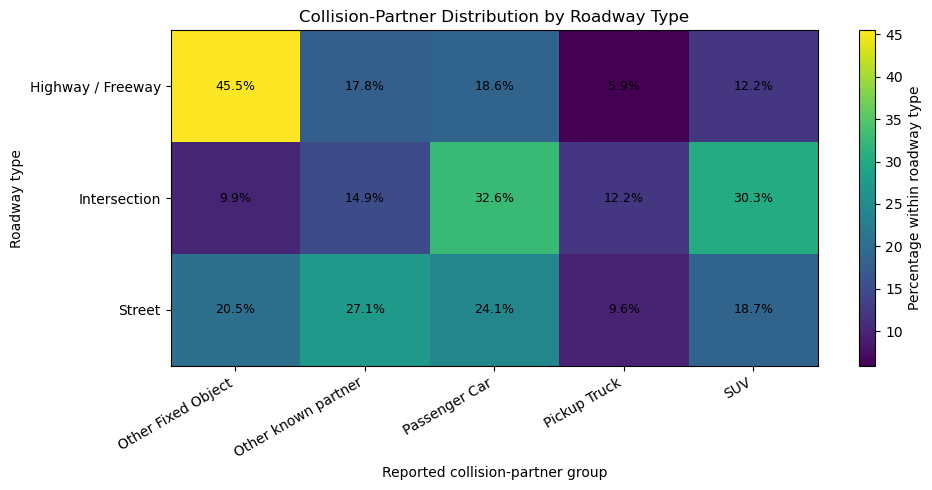

In [17]:
plt.figure(figsize=(10, 5))

plt.imshow(row_percentages.values, aspect="auto")
plt.colorbar(label="Percentage within roadway type")

plt.xticks(
    range(len(row_percentages.columns)),
    row_percentages.columns,
    rotation=30,
    ha="right"
)

plt.yticks(
    range(len(row_percentages.index)),
    row_percentages.index
)

for i in range(row_percentages.shape[0]):
    for j in range(row_percentages.shape[1]):
        plt.text(
            j, i,
            f"{row_percentages.iloc[i, j]:.1f}%",
            ha="center",
            va="center",
            fontsize=9
        )

plt.title("Collision-Partner Distribution by Roadway Type")
plt.xlabel("Reported collision-partner group")
plt.ylabel("Roadway type")
plt.tight_layout()
plt.show()

## Discussion of findings
This section combines the descriptive tables, visualisations and inferential test. It distinguishes the strongest observed patterns from statistical evidence, considers missing and repeated reports, and explains why the findings cannot estimate real-world crash risk.

In [18]:
print("Most frequent roadway categories:")
display(frequency_table(tesla, "Roadway Type").head(5))

print("Most frequent known collision-partner categories:")
display(frequency_table(tesla, "Crash With").head(8))

print("Chi-square analysis sample:", len(analysis))
print("Eligible roadway types:", analysis["Roadway Clean"].nunique())
print("Collision-partner groups:", analysis["Crash Partner Group"].nunique())

Most frequent roadway categories:


,Roadway Type,Count,Percentage
0,Unknown,900,41.59
1,Highway / Freeway,691,31.93
2,Intersection,250,11.55
3,Street,242,11.18
4,Rural Road,42,1.94


Most frequent known collision-partner categories:


,Crash With,Count,Percentage
0,Unknown,1200,55.45
1,Other Fixed Object,310,14.33
2,Passenger Car,215,9.94
3,SUV,168,7.76
4,Pickup Truck,73,3.37
5,"Other, see Narrative",72,3.33
6,Pole / Tree,52,2.40
7,Heavy Truck,23,1.06


Chi-square analysis sample: 897
Eligible roadway types: 3
Collision-partner groups: 5
